In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder, StandardScaler
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
cols = ['age','workclass','fnlwgt','education','education_num','marital_status',
        'occupation','relationship','race','sex','capital_gain','capital_loss',
        'hours_per_week','native_country','income']
df = pd.read_csv(url, names=cols, sep=', ', engine='python', na_values='?')

In [ ]:
# 1. Check missing values
print(df.isnull().sum())

# 2. Drop rows with missing values
df.dropna(inplace=True)

# 3. Encode target variable
df['income_binary'] = (df['income'].str.strip() == '>50K').astype(int)

# 4. Encode categorical columns
cat_cols = ['workclass','education','marital_status','occupation',
            'relationship','race','sex','native_country']
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# 5. Feature scaling (for continuous features)
scaler = StandardScaler()
num_cols = ['age','fnlwgt','education_num','capital_gain','capital_loss','hours_per_week']
df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])

age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64


In [ ]:
X = df_encoded.drop(['income', 'income_binary'], axis=1)
y = df_encoded['income_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=38  # YOUR SEED
)

In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_linear = lr.predict(X_test)  # continuous probabilities

# Threshold at median
median_val = np.median(y_pred_linear)
y_class_linear = (y_pred_linear >= median_val).astype(int)
print(f"Median threshold used: {median_val:.4f}")

Median threshold used: 0.2341


In [ ]:
log_reg = LogisticRegression(max_iter=1000, random_state=38)
log_reg.fit(X_train, y_train)
y_pred_proba = log_reg.predict_proba(X_test)[:, 1]

# Threshold at 0.5
y_class_logistic = (y_pred_proba >= 0.5).astype(int)

In [ ]:
log_reg = LogisticRegression(max_iter=1000, random_state=38)
log_reg.fit(X_train, y_train)
y_pred_proba = log_reg.predict_proba(X_test)[:, 1]

# Threshold at 0.5
y_class_logistic = (y_pred_proba >= 0.5).astype(int)

In [ ]:
# Restore original sex column for splitting
df_encoded['sex_orig'] = df['sex'].values[:len(df_encoded)]

X_full = df_encoded.drop(['income','income_binary','sex_orig'], axis=1)
y_full = df_encoded['income_binary']

# Full model
log_full = LogisticRegression(max_iter=1000, random_state=38)
log_full.fit(X_full, y_full)

# Subgroup A: Male
mask_m = df_encoded['sex_orig'] == 'Male'
log_male = LogisticRegression(max_iter=1000, random_state=38)
log_male.fit(X_full[mask_m], y_full[mask_m])

# Subgroup B: Female
mask_f = df_encoded['sex_orig'] == 'Female'
log_female = LogisticRegression(max_iter=1000, random_state=38)
log_female.fit(X_full[mask_f], y_full[mask_f])

LogisticRegression(max_iter=1000, random_state=38)

In [ ]:
# Full model
features_full = [c for c in X_train.columns]
log_full2 = LogisticRegression(max_iter=1000, random_state=38)
log_full2.fit(X_train[features_full], y_train)

# Reduced model (without education_num)
features_reduced = [c for c in features_full if c != 'education_num']
log_reduced = LogisticRegression(max_iter=1000, random_state=38)
log_reduced.fit(X_train[features_reduced], y_train)

# Compare coefficients for 4 features
compare_features = ['age','hours_per_week','capital_gain','capital_loss']
for f in compare_features:
    idx_full = list(features_full).index(f)
    idx_red = list(features_reduced).index(f)
    c_full = log_full2.coef_[0][idx_full]
    c_red = log_reduced.coef_[0][idx_red]
    pct_change = abs((c_red - c_full)/c_full)*100
    print(f"{f}: Full={c_full:.4f}, Reduced={c_red:.4f}, Change={pct_change:.1f}%")

age: Full=0.3081, Reduced=0.3073, Change=0.3%
hours_per_week: Full=0.3469, Reduced=0.3487, Change=0.5%
capital_gain: Full=2.3899, Reduced=2.3762, Change=0.6%
capital_loss: Full=0.2621, Reduced=0.2629, Change=0.3%


In [ ]:
# High confidence WRONG predictions
proba_test = log_reg.predict_proba(X_test)[:, 1]
y_test_arr = y_test.values

# False positives with high confidence (P >= 0.75 but actual = 0)
fp_mask = (proba_test >= 0.75) & (y_test_arr == 0)
# False negatives with high confidence (P <= 0.25 but actual = 1)
fn_mask = (proba_test <= 0.25) & (y_test_arr == 1)

adversarial = X_test[fp_mask | fn_mask].copy()
adversarial['actual'] = y_test_arr[fp_mask | fn_mask]
adversarial['predicted_proba'] = proba_test[fp_mask | fn_mask]

print(f"Total adversarial cases: {len(adversarial)}")
print(f"As % of test set: {len(adversarial)/len(X_test)*100:.2f}%")

# Sample 50
if len(adversarial) > 50:
    adversarial_50 = adversarial.sample(50, random_state=38)
else:
    adversarial_50 = adversarial

# Demographics of these 50
print(adversarial_50.describe())

Total adversarial cases: 471
As % of test set: 5.20%
             age     fnlwgt  education_num  capital_gain  capital_loss  \
count  50.000000  50.000000      50.000000     50.000000     50.000000   
mean    0.479814   0.231847       0.258314     -0.121415     -0.124495   
std     0.902792   1.112846       1.326443      0.105053      0.665320   
min    -0.794697  -1.572228      -3.184887     -0.147445     -0.218586   
25%    -0.242713  -0.544046      -0.439738     -0.147445     -0.218586   
50%     0.309271   0.106801      -0.047574     -0.147445     -0.218586   
75%     1.089661   0.769877       1.128918     -0.147445     -0.218586   
max     3.240494   3.247016       2.305411      0.368068      4.485938   

       hours_per_week     actual  predicted_proba  
count       50.000000  50.000000        50.000000  
mean         0.191052   0.720000         0.336185  
std          1.159631   0.453557         0.317853  
min         -2.999322   0.000000         0.013839  
25%         -0.07773

   threshold     DP     EO     PP
0       0.05  2.020  1.030  1.490
1       0.15  2.974  1.141  1.122
2       0.25  3.298  1.207  1.070
3       0.35  3.492  1.244  1.042
4       0.45  3.544  1.243  1.026
5       0.55  3.554  1.244  1.023
6       0.65  3.615  1.278  1.033
7       0.75  3.464  1.254  1.058
8       0.85  3.649  1.264  1.013
9       0.95  3.998  0.842  1.093


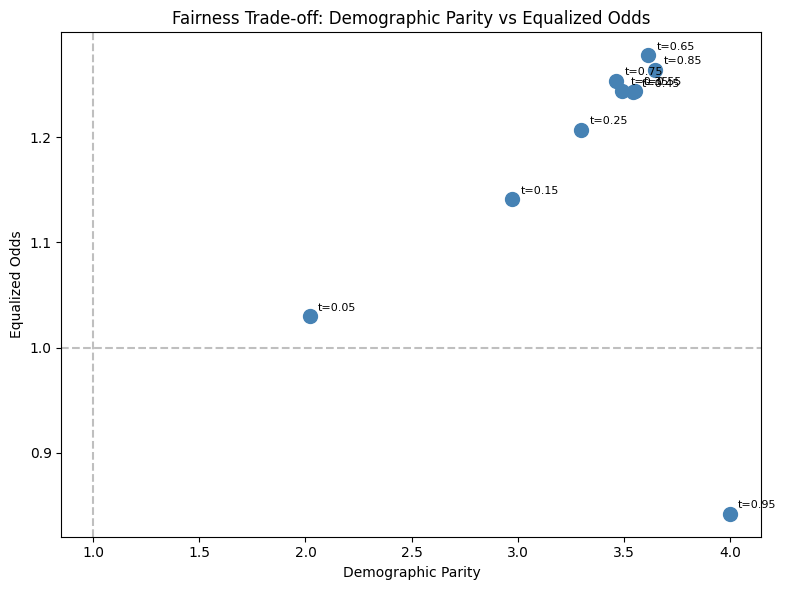

In [ ]:
# ============ PART 2.4 FIXED ============
thresholds = [round(0.05 + 0.1*i, 2) for i in range(10)]

# FIX: use .loc (label-based) instead of .iloc (position-based)
sex_test = df_encoded['sex_orig'].loc[y_test.index]
mask_A = (sex_test == 'Male').values    # convert to numpy boolean array
mask_B = (sex_test == 'Female').values  # convert to numpy boolean array

y_test_arr = y_test.values  # numpy array

results = []
for t in thresholds:
    preds = (proba_test >= t).astype(int)

    # Demographic Parity
    dp = preds[mask_A].mean() / (preds[mask_B].mean() + 1e-9)

    # Equalized Odds
    tpr_a = ((preds[mask_A]==1) & (y_test_arr[mask_A]==1)).sum() / max((y_test_arr[mask_A]==1).sum(), 1)
    tpr_b = ((preds[mask_B]==1) & (y_test_arr[mask_B]==1)).sum() / max((y_test_arr[mask_B]==1).sum(), 1)
    fpr_a = ((preds[mask_A]==1) & (y_test_arr[mask_A]==0)).sum() / max((y_test_arr[mask_A]==0).sum(), 1)
    fpr_b = ((preds[mask_B]==1) & (y_test_arr[mask_B]==0)).sum() / max((y_test_arr[mask_B]==0).sum(), 1)
    eo = min(tpr_a / (tpr_b + 1e-9), fpr_a / (fpr_b + 1e-9))

    # Predictive Parity
    pp_a_mask = mask_A & (preds == 1)
    pp_b_mask = mask_B & (preds == 1)
    pp_a = (y_test_arr[pp_a_mask] == 1).mean() if pp_a_mask.sum() > 0 else 0
    pp_b = (y_test_arr[pp_b_mask] == 1).mean() if pp_b_mask.sum() > 0 else 0
    pp = pp_a / (pp_b + 1e-9)

    results.append({'threshold': t, 'DP': round(dp,3), 'EO': round(eo,3), 'PP': round(pp,3)})

results_df = pd.DataFrame(results)
print(results_df)

# Plot
plt.figure(figsize=(8,6))
for _, row in results_df.iterrows():
    plt.scatter(row['DP'], row['EO'], s=100, color='steelblue')
    plt.annotate(f"t={row['threshold']}", (row['DP'], row['EO']),
                 textcoords="offset points", xytext=(6, 4), fontsize=8)
plt.xlabel('Demographic Parity')
plt.ylabel('Equalized Odds')
plt.title('Fairness Trade-off: Demographic Parity vs Equalized Odds')
plt.axhline(1.0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(1.0, color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('fairness_tradeoff.png', dpi=150)
plt.show()